# Tumor-edge：3,000 基因背景与稀疏通讯变化

选择 **cccphe**，执行 **Restart Kernel → Run All**。这是独立实验，原模拟和原 Notebook 保留。8,000 个细胞、五种类型、四个真实 MI、32 维 Z；沿用原 KNN30、sigma=20 µm 和 CCC 定义。

**背景：**3,000 个编码器基因，其中 150 个 LR 基因、25 个标记基因、1,200 个类型模块基因、800 个共享状态基因和 825 个管家基因。背景通过 scCube 生成并进行显式类型均值校准，再加入共享状态、文库大小和负二项变异；这些是公开记录的模拟假设。两个半环的类型、径向位置和原始非 LR 表达逐对匹配。

**通讯注入：**两个边缘 MI 涉及 24 个基因（面板的 0.8%）；sender ligand/receiver receptor 在激活位置的条件期望最多增加到原来的 2 倍，使用 Poisson 计数增量，保留零表达与噪声。只修改真实表达，不修改 CCC 矩阵。文库归一化可能带来小幅间接背景差异，实际 LR 计数比例等审计写入 NAS。此实验不是严格的 spatial-pairing-only 模拟，也不保证某种方法获胜。

**模型：**复用 NMF 初始化、CCC 预训练、受保护的 CCC＋表达联合训练；表达梯度上限 10%，验证 CCC 波动上限 0.5%。额外 24 个模拟响应基因和 12 个阴性对照只作表达标签，不进入编码器。图表保持原 Notebook 的顺序，末尾保留 GraphST 和 CellCharter(PCA) 比较。完整数据、模型和图片均写入新的 NAS 输出目录，已完成且一致的结果可复用。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,contextlib
import matplotlib.pyplot as plt
import torch
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.simulation.dependencies import prepare_environment
from phenoniche.simulation.response_simulation import ExpressionExperimentConfig
from phenoniche.simulation.response_experiment import run_expression_experiment
from phenoniche.simulation.joint_reporting import JointExpressionReport
from phenoniche.training import set_seed
from phenoniche.simulation.rich_background import prepare_rich_background
config=ExpressionExperimentConfig.from_json(ROOT/'config/tumor_edge_gene_rich_expression.json')
OUTPUT=Path(config.output_dir)
OUTPUT.mkdir(parents=True,exist_ok=True)
torch.set_num_threads(6)
set_seed(config.seed)
if config.device.startswith('cuda:') and not torch.cuda.is_available():
    raise RuntimeError('请在服务器 cccphe GPU 环境中运行')
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    prepare_environment()
    prepare_rich_background(config.base_simulation_config,ROOT/'config/tumor_edge_gene_rich_background.json')
    run_expression_experiment(config)
report=JointExpressionReport(OUTPUT)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. 模拟组织与模型 niche

显示原始聚类编号，不用真实标签替换模型输出。CCC-only 与联合模型使用相同数据，联合模型 K=4–15 的选择只用训练/验证集，不读取真实 niche。

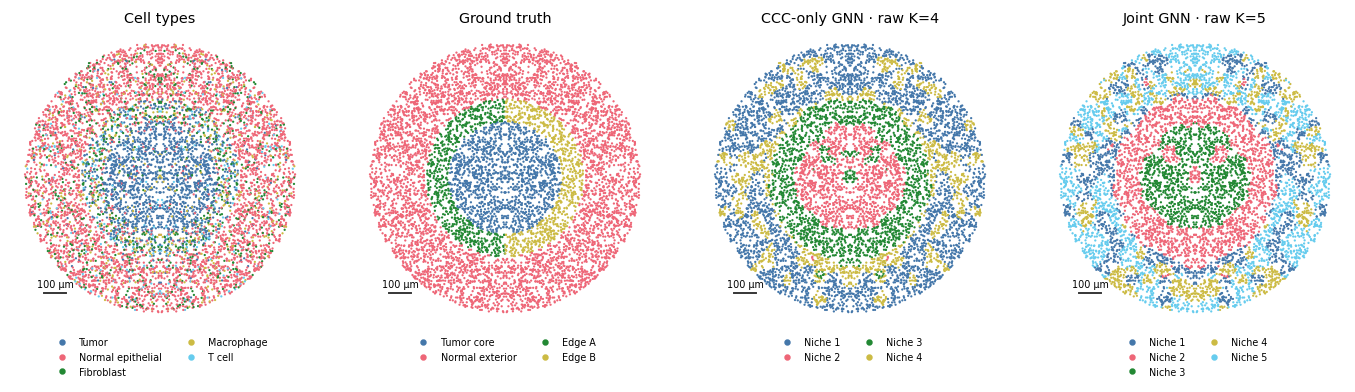

In [2]:
show(report.spatial_comparison())

## 2. 四个真实通讯程序是否恢复

上下两行使用相同数值尺度；下方由 **Z @ H** 沿预先定义的 MI 字典投影，汇总全部 32 个程序的贡献，不强制一个 MI 对应一个 Z 维度。真实字典只用于训练后的评估。

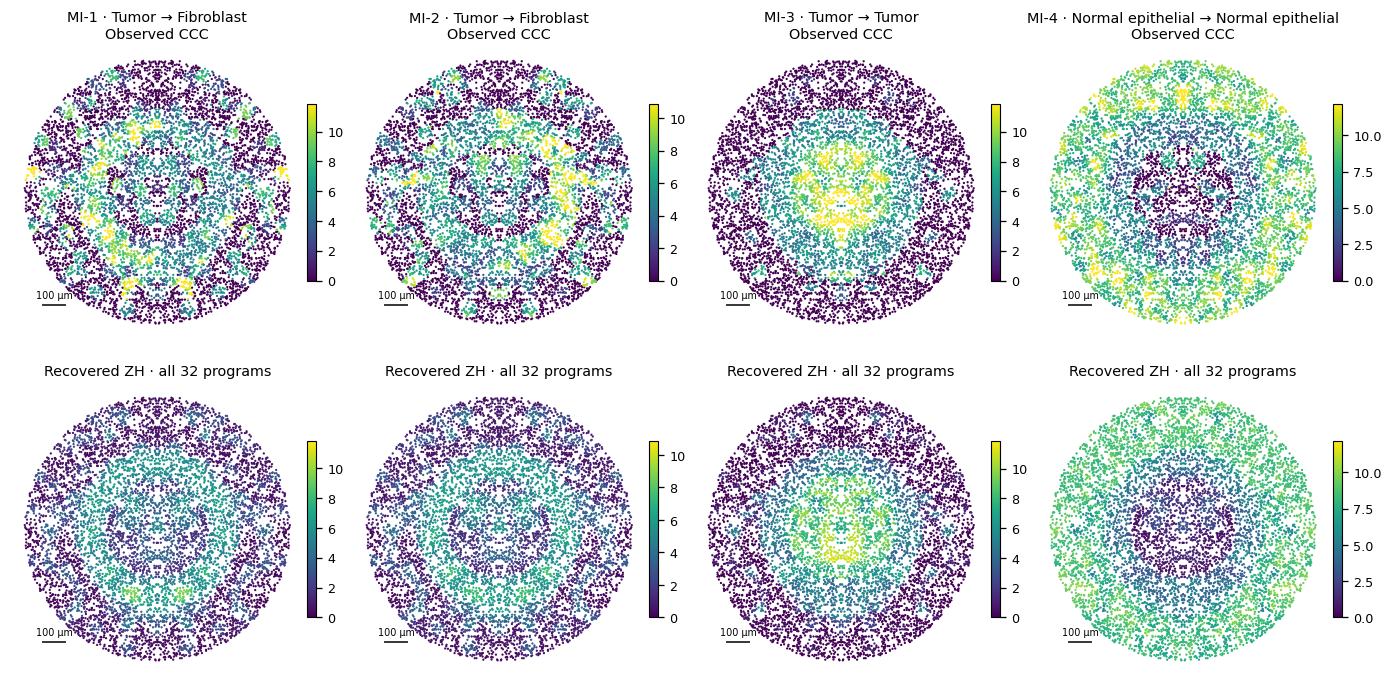

In [3]:
show(report.communication_recovery())

## 3. 基因表达是否对应

同一列是同一个模拟响应基因；每个 niche 内按该基因的 receiver 类型汇总空间加权表达，再减去该类型中这个基因的观测均值。上下两幅共用色标和参考均值，蓝色较低、红色较高。热图展示**全组织（含训练和验证中心）的描述性结果**。下方另用空间测试集对比基线、冻结版和联合版的 RMSE，并显示测试覆盖；严格两跳划分可能排除部分区域；下方测试覆盖图给出实际覆盖，不对未覆盖区域宣称独立验证。

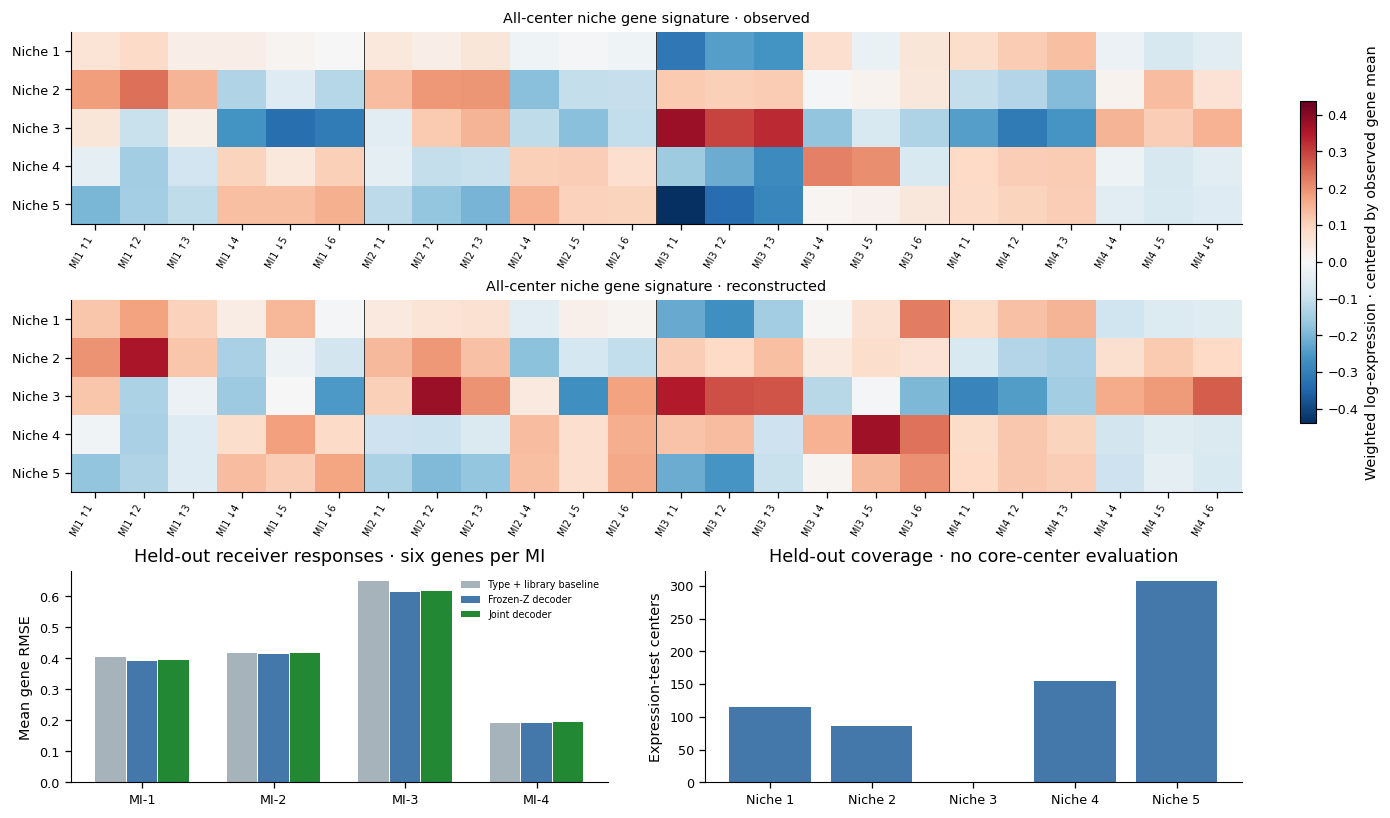

In [4]:
show(report.expression_recovery())

## 4. Niche 与细胞类型的关系

同一物理细胞对权重计算的空间加权组成。此图仅用于下游解释，不增加细胞组成重建损失。

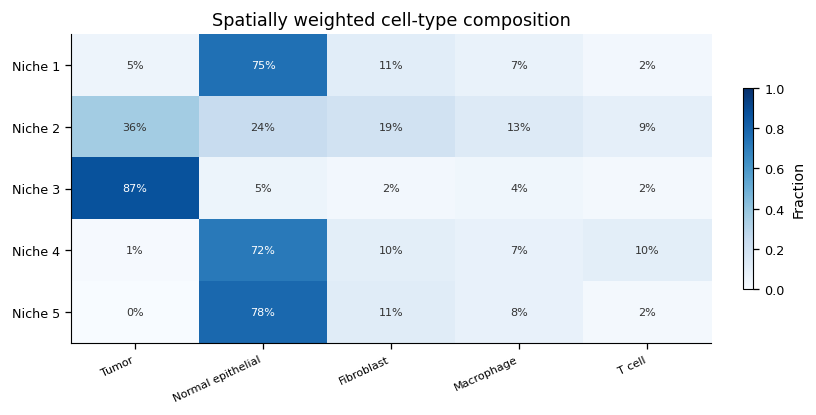

In [5]:
show(report.niche_cell_types())

## 5. 每个 niche 的 top10 CCC

对 niche 内 Z 取均值后乘 H：**mean(Z | niche) @ H**。表中列出 sender→receiver→LR、平均重构强度及贡献最大的程序；niche 可由多个程序共同形成。排序按原始 CCC 单位计算，不代表临床显著性或因果作用。

In [6]:
display(report.top_ccc.rename(columns={'niche':'Niche','rank':'Rank','sender':'Sender','receiver':'Receiver','LR':'Ligand–Receptor','mean_reconstructed_CCC':'Mean CCC','main_program':'Main program'}).drop(columns=['LR_id']).style.format({'Mean CCC':'{:.3f}'}).hide(axis='index'))

Niche,Rank,Sender,Receiver,Ligand–Receptor,Mean CCC,Main program
1,1,Normal epithelial,Normal epithelial,DEFB4A–CCR6,2.240,1
1,2,Normal epithelial,Normal epithelial,BMP10–BMPR1A,2.163,1
1,3,Normal epithelial,Normal epithelial,IAPP–RAMP1,1.952,1
1,4,Fibroblast,Fibroblast,COL4A1–ITGB1,1.904,1
1,5,Fibroblast,Fibroblast,BCAN–NRCAM,1.824,1
1,6,Fibroblast,Fibroblast,FGF3–FGFR2,1.701,1
1,7,Normal epithelial,Normal epithelial,TSHB–ADRB3,1.564,1
1,8,Macrophage,Macrophage,ARTN–RET,1.283,1
1,9,Normal epithelial,Normal epithelial,DSC1–DSG2,1.277,1
1,10,Normal epithelial,Normal epithelial,PLAT–ITGB2,1.270,1


## 6. 训练 loss

分别显示 CCC 预训练和联合阶段的两个任务，数值尺度不同。虚线标出选中的 joint epoch，点线表示验证 CCC 的接受上限；epoch 0 是冻结版起点。

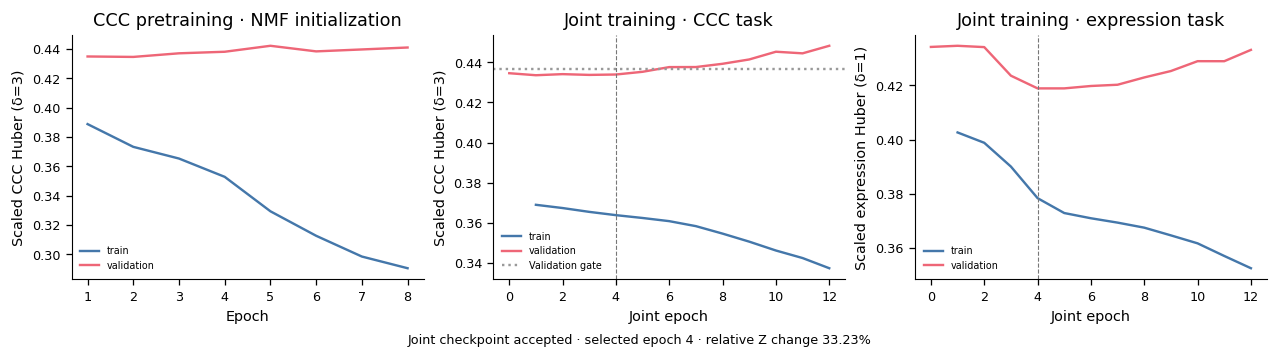

In [7]:
show(report.curves())

## 7. 模拟数据与模型结果总图

真实四区域、细胞类型、CCC-only 和联合 niche 并排显示；下方比较四个真实 MI 与恢复的通讯强度。**仅这张总图**使用训练中心拟合的标签颜色映射，便于直观对照；第一图和表中仍保留原始编号。底部指标由 held-out test 实际计算，标签匹配未进入训练或 K 选择。高分是本模拟、当前随机种子的结果，不是临床验证。全部 PNG/PDF/SVG、指标和模型数组在 NAS 输出目录。

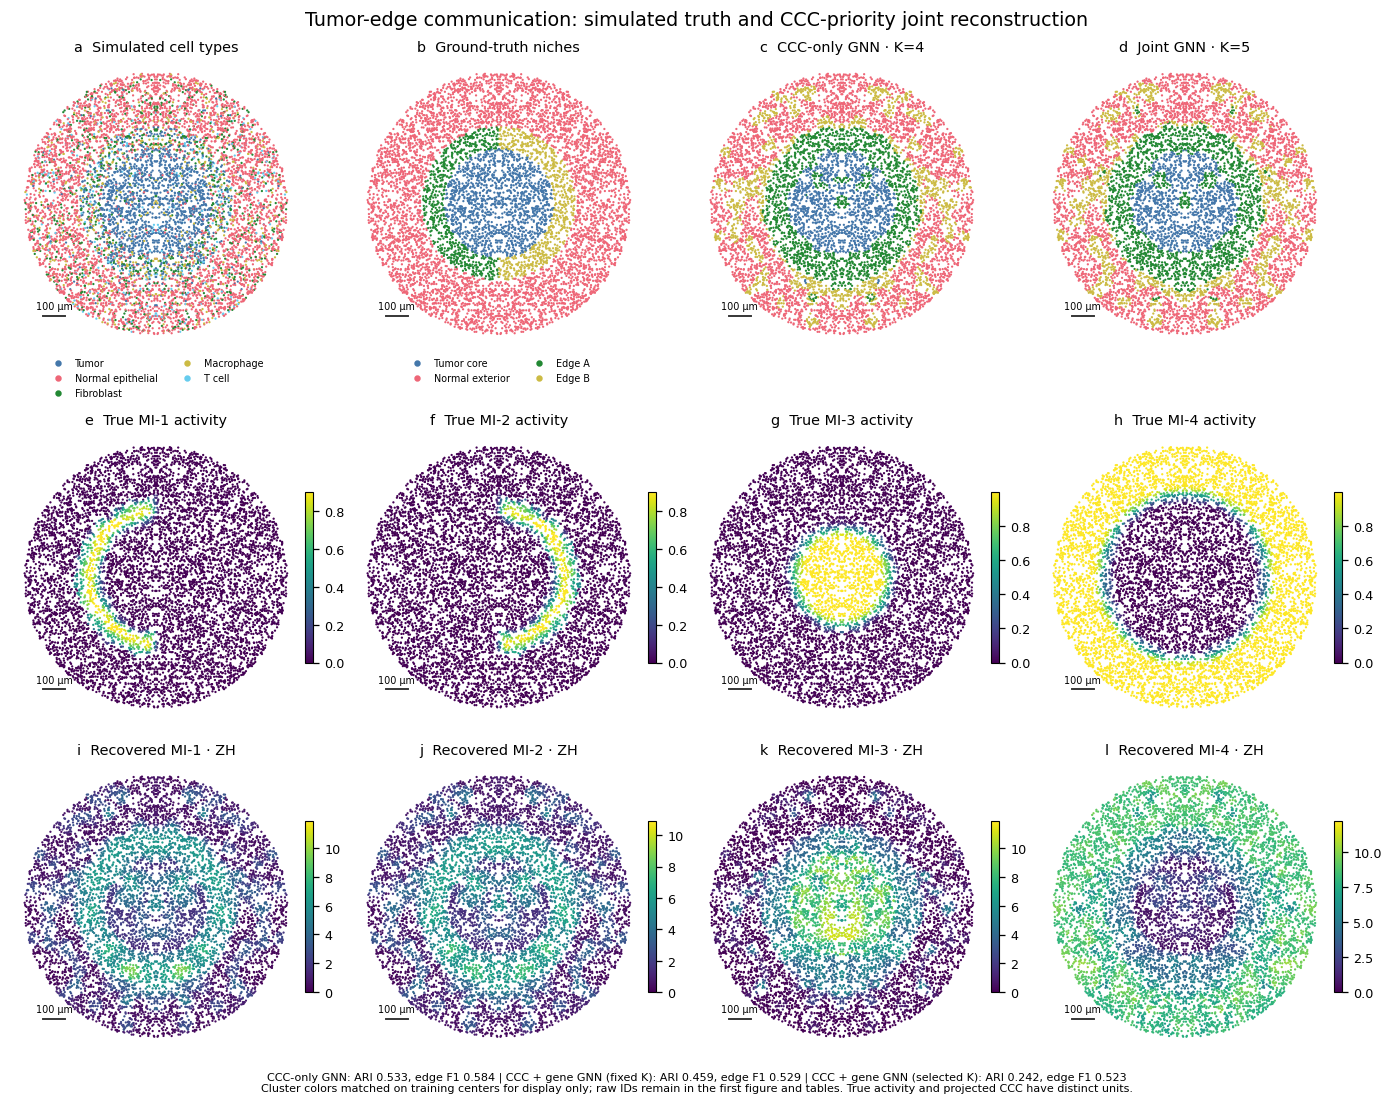

In [8]:
show(report.summary_figure())

## 8. 与空间聚类 baseline 比较

使用公开的 [GraphST](https://github.com/JinmiaoChenLab/GraphST) 和 [CellCharter](https://github.com/CSOgroup/cellcharter)。代码和配置位于项目 `baselines/`，结果存入当前 NAS 实验的 `baseline_comparison/`。

**比较协议：**同样的 8,000 个细胞和原始 3,000 个基因，新增响应/阴性对照基因不进入 baseline；同样的原始 KNN30 邻域拓扑。预处理、表示模型和聚类参数只在原 GNN 训练区域拟合，固定 K=4，不按真实标签选参数。GraphST 使用官方稀疏模型＋作者 `emb` 表示＋KMeans；CellCharter 使用 **PCA32＋一跳空间聚合＋官方 GMM**，明确是 PCA 变体，未声称使用 scVI。两者各自保留原方法的权重/归一化，并记录配置和运行时间。

CCC-AE 使用预计算 CCC；细胞组成方法使用类型标签；我们的 GNN 使用 CCC 与类型分层表达监督。其他表达/空间 baseline 不得到这些监督信息，因此这是一项**同数据、不同信息条件**的比较。现有 GNN checkpoint 不重训、不改参数。

In [9]:
sys.path.insert(0,str(ROOT))
from baselines.benchmark import run_comparison
from baselines.reporting import BaselineReport
with (OUTPUT/'baseline_comparison_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    BASELINE_OUTPUT=run_comparison(OUTPUT)
    baseline_report=BaselineReport(OUTPUT,BASELINE_OUTPUT)

### 空间聚类图

第一图保留各方法的原始 cluster ID；第二图仅为看图方便，用训练中心拟合颜色映射。真实标签均在拟合结束后才用于评价，不能把配色匹配当成预测。所有图含训练区域，下方 ARI 是全组织描述性恢复指标。

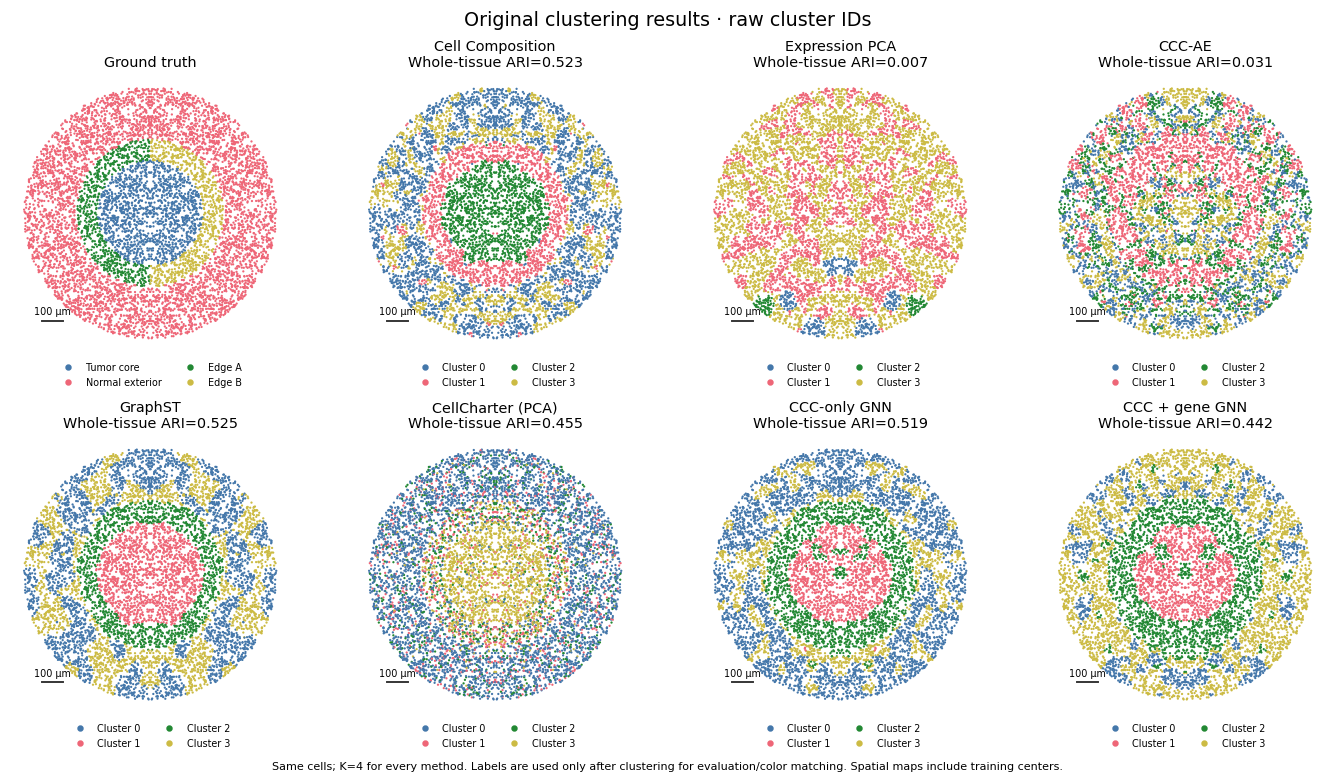

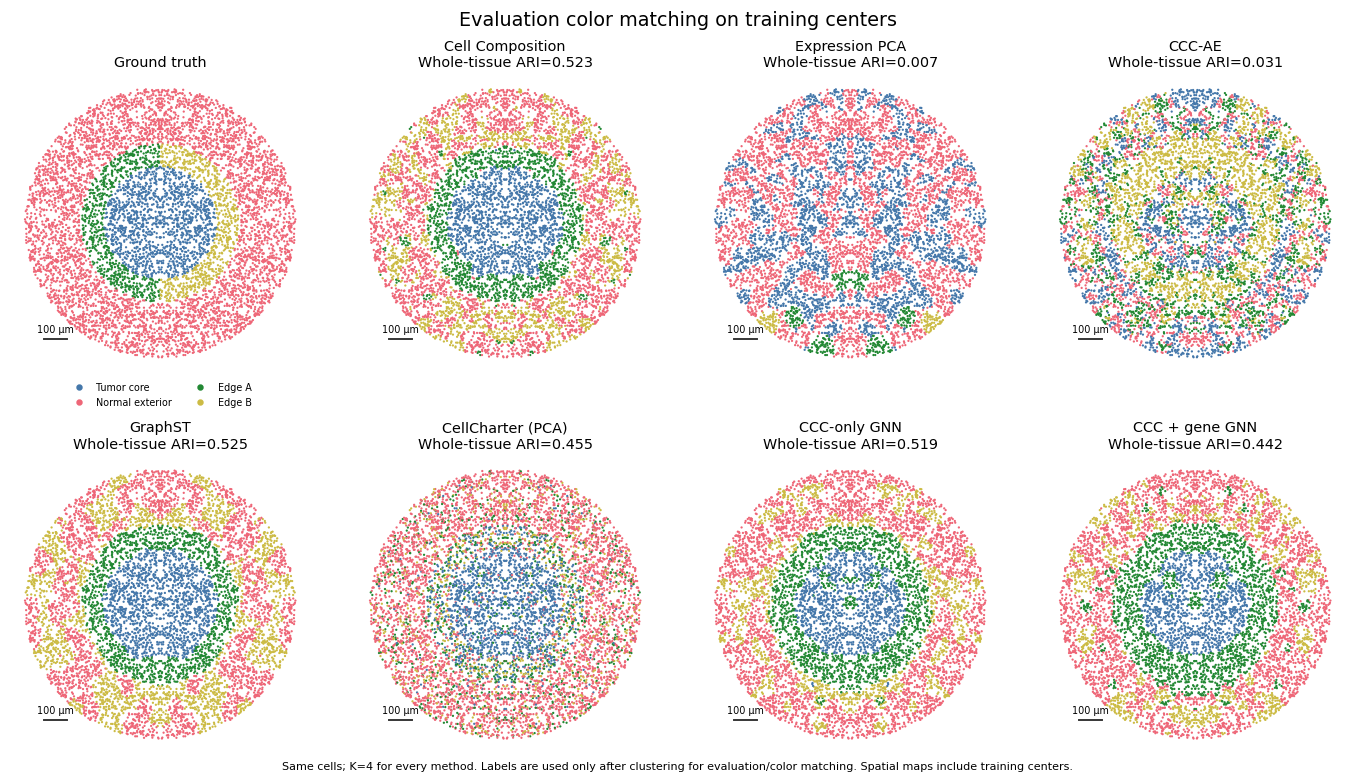

In [10]:
show(baseline_report.spatial(align=False))
show(baseline_report.spatial(align=True))

### 同一批空间测试中心上的评价

GraphST 的重构需要两跳图输入，因此所有方法统一使用原空间测试划分再加两跳隔离的中心集合。表中 `n`、`n_true_edge` 给出实际覆盖；未覆盖的区域不宣称已独立验证。ARI/NMI 使用原始聚类编号；F1/IoU 和 A/B accuracy 的映射只在训练中心拟合。固定 K=4 是预先定义的公平比较，不是无监督发现区域数的证据。当前只有一个模拟/训练随机种子，结果用于框架比较。

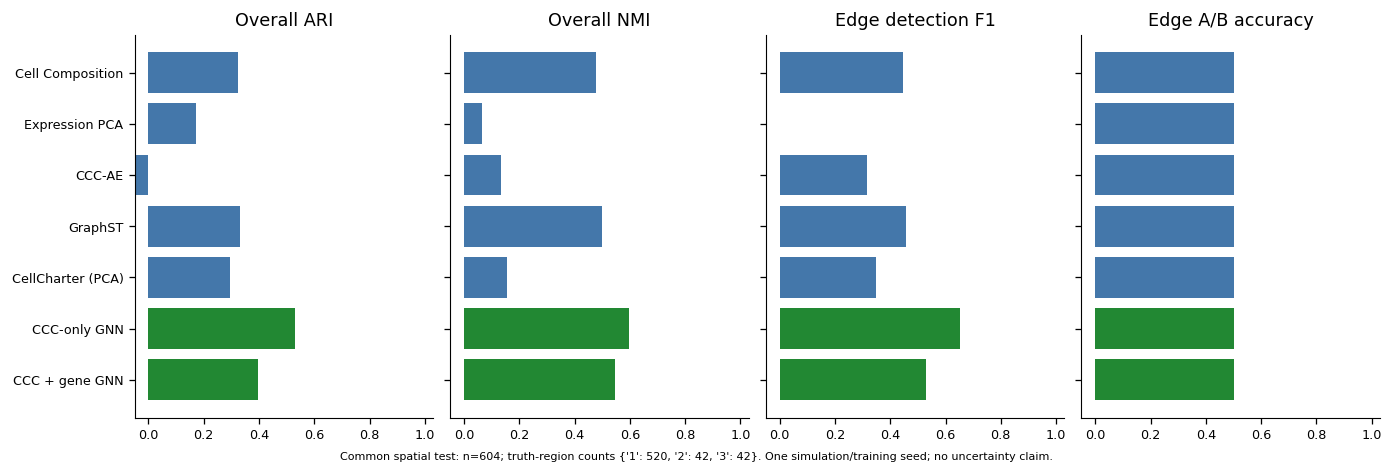

method,K,n,n_true_edge,overall_ARI,overall_NMI,edge_F1,edge_IoU,edge_AB_ARI,edge_AB_accuracy
Cell Composition,4,604,84,0.325,0.478,0.444,0.286,-0.002,0.500
Expression PCA,4,604,84,0.171,0.066,0.000,0.000,-0.012,0.500
CCC-AE,4,604,84,-0.045,0.133,0.317,0.188,-0.001,0.500
CCC-only GNN,4,604,84,0.531,0.596,0.651,0.483,-0.001,0.500
CCC + gene GNN,4,604,84,0.395,0.546,0.530,0.361,0.000,0.500
GraphST,4,604,84,0.330,0.498,0.456,0.295,-0.002,0.500
CellCharter (PCA),4,604,84,0.295,0.155,0.347,0.210,-0.018,0.500
CellCharter (PCA; common KMeans),4,604,84,0.186,0.239,0.054,0.028,-0.014,0.500


In [11]:
show(baseline_report.metric_plot())
display(baseline_report.metric_table().style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_IoU','edge_AB_ARI','edge_AB_accuracy']}).hide(axis='index'))

### 全组织描述性指标与计算条件

此表补充包括核心区在内的全组织恢复效果，含训练中心，不能解释成独立泛化评估。空间 baseline 没有 directed CCC decoder，因此不编造其 CCC 重构指标。方法原始输出、checkpoint、输入基因、严格公共测试划分、软件版本和官方源码 commit 均保存在 NAS 中。

In [12]:
display(baseline_report.metrics.query("scope == 'all_centers_descriptive'")[['method','K','n','overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']].style.format({k:'{:.3f}' for k in ['overall_ARI','overall_NMI','edge_F1','edge_AB_accuracy']}).hide(axis='index'))

method,K,n,overall_ARI,overall_NMI,edge_F1,edge_AB_accuracy
Cell Composition,4,8000,0.523,0.640,0.564,0.500
Expression PCA,4,8000,0.007,0.018,0.068,0.500
CCC-AE,4,8000,0.031,0.131,0.475,0.501
CCC-only GNN,4,8000,0.519,0.627,0.586,0.500
CCC + gene GNN,4,8000,0.442,0.565,0.568,0.500
GraphST,4,8000,0.525,0.688,0.540,0.500
CellCharter (PCA),4,8000,0.455,0.323,0.410,0.500
CellCharter (PCA; common KMeans),4,8000,0.281,0.306,0.274,0.504
